# Titanic Survival Prediction — Machine Learning

A classification project that predicts whether a passenger survived the Titanic disaster.

**Models compared:** Random Forest and Support Vector Machine (SVM).

This notebook uses a stratified 60/20/20 split:
- 60% training
- 20% validation
- 20% holdout testing

The official Kaggle `test.csv` has no `Survived` labels, so its predictions are saved as submission files rather than evaluated for accuracy.

## 1. Import Libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Load the Data

In [2]:
train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
kaggle_test = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")

print("Training shape:", train.shape)
print("Kaggle test shape:", kaggle_test.shape)

display(train.head())
display(kaggle_test.head())

Training shape: (891, 12)
Kaggle test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 3. Initial Data Exploration

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
\nMissing values in training data:


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

\nTarget distribution:


Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

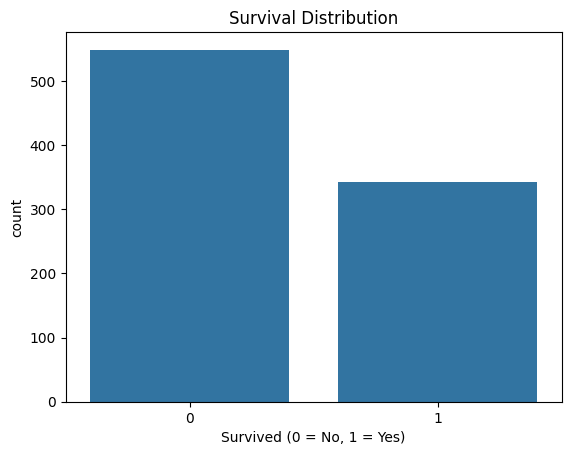

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [3]:
print("Training information:")
train.info()

print("\\nMissing values in training data:")
display(train.isnull().sum().sort_values(ascending=False))

print("\\nTarget distribution:")
display(train["Survived"].value_counts())
display(train["Survived"].value_counts(normalize=True).rename("proportion"))

sns.countplot(data=train, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

display(train.describe(include="all").T)

## 4. Feature Engineering

In [4]:
def prepare_features(data):
    """Create features while leaving missing-value handling to the pipelines."""
    data = data.copy()

    # Extract passenger title from the Name column.
    data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    data["Title"] = data["Title"].replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })
    data["Title"] = data["Title"].replace({
        "Lady": "Rare", "Countess": "Rare", "Capt": "Rare",
        "Col": "Rare", "Don": "Rare", "Dr": "Rare", "Major": "Rare",
        "Rev": "Rare", "Sir": "Rare", "Jonkheer": "Rare",
        "Dona": "Rare"
    })

    # Family-related features.
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    # Use the first letter of Cabin when available.
    data["CabinDeck"] = data["Cabin"].str[0]

    # Remove identifiers and high-cardinality text fields.
    data = data.drop(
        columns=["PassengerId", "Name", "Ticket", "Cabin", "Survived"],
        errors="ignore"
    )

    return data


y = train["Survived"].astype(int)
X = prepare_features(train)
X_kaggle = prepare_features(kaggle_test)

print("Features shape:", X.shape)
print("Kaggle features shape:", X_kaggle.shape)
display(X.head())

Features shape: (891, 11)
Kaggle features shape: (418, 11)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,CabinDeck
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,NaN
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,C
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,NaN
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,C
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,NaN


## 5. Split the Labeled Data (60/20/20)

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_holdout, y_val, y_holdout = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Holdout test:", X_holdout.shape)

Train: (534, 11)
Validation: (178, 11)
Holdout test: (179, 11)


## 6. Preprocessing

In [6]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Categorical features: ['Sex', 'Embarked', 'Title', 'CabinDeck']


## 7. Random Forest — Hyperparameter Tuning

Preprocessing is inside the Pipeline. This ensures that imputers and encoders are fitted only on each training fold during cross-validation, reducing data leakage.

In [7]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])

rf_params = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt"]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best cross-validation accuracy:", rf_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 400}
Best cross-validation accuracy: 0.8202786104743431


## 8. Support Vector Machine (SVM) — Hyperparameter Tuning

In [8]:
svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(class_weight="balanced"))
])

svm_params = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train, y_train)

best_svm = svm_grid.best_estimator_
print("Best SVM parameters:", svm_grid.best_params_)
print("Best cross-validation accuracy:", svm_grid.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best SVM parameters: {'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
Best cross-validation accuracy: 0.8183918180215131


## 9. Validation Evaluation

In [9]:
def evaluate_model(model, X_data, y_true, model_name):
    predictions = model.predict(X_data)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0)
    }

    print(f"\\n{model_name} classification report:")
    print(classification_report(
        y_true, predictions,
        target_names=["Not Survived", "Survived"],
        zero_division=0
    ))

    return metrics, predictions


rf_val_metrics, rf_val_predictions = evaluate_model(
    best_rf, X_val, y_val, "Random Forest"
)

svm_val_metrics, svm_val_predictions = evaluate_model(
    best_svm, X_val, y_val, "SVM"
)

validation_results = pd.DataFrame([rf_val_metrics, svm_val_metrics])
display(validation_results.sort_values("F1-score", ascending=False))

\nRandom Forest classification report:
              precision    recall  f1-score   support

Not Survived       0.84      0.93      0.88       110
    Survived       0.86      0.72      0.78        68

    accuracy                           0.85       178
   macro avg       0.85      0.82      0.83       178
weighted avg       0.85      0.85      0.85       178

\nSVM classification report:
              precision    recall  f1-score   support

Not Survived       0.83      0.85      0.84       110
    Survived       0.75      0.72      0.74        68

    accuracy                           0.80       178
   macro avg       0.79      0.79      0.79       178
weighted avg       0.80      0.80      0.80       178



,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.848315,0.859649,0.720588,0.784000
1,SVM,0.803371,0.753846,0.720588,0.736842


## 10. Confusion Matrices

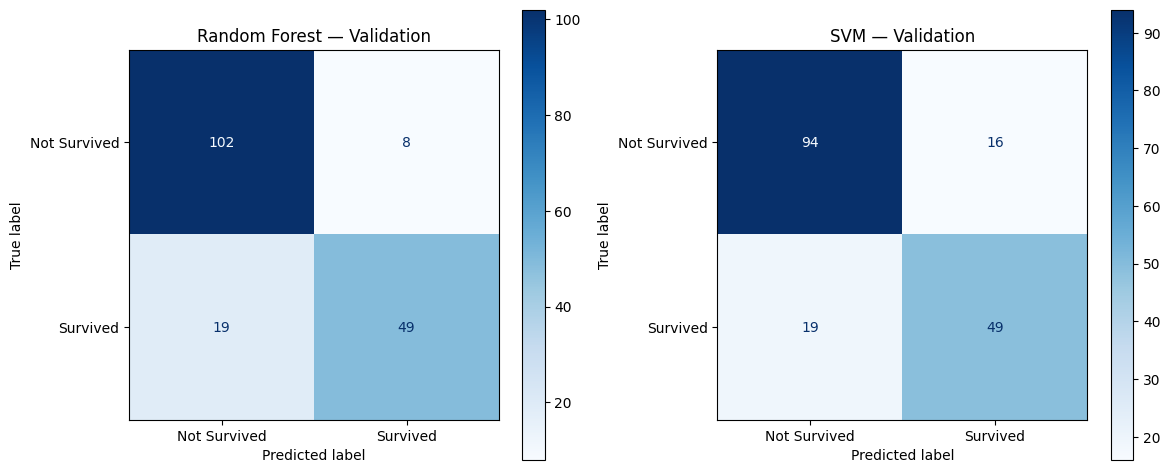

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], rf_val_predictions, "Random Forest"),
    (axes[1], svm_val_predictions, "SVM")
]:
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        display_labels=["Not Survived", "Survived"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(f"{title} — Validation")

plt.tight_layout()
plt.show()

## 11. Holdout Test Evaluation

In [11]:
# The holdout set is kept separate from model tuning.
rf_holdout_metrics, rf_holdout_predictions = evaluate_model(
    best_rf, X_holdout, y_holdout, "Random Forest — Holdout"
)

svm_holdout_metrics, svm_holdout_predictions = evaluate_model(
    best_svm, X_holdout, y_holdout, "SVM — Holdout"
)

holdout_results = pd.DataFrame([rf_holdout_metrics, svm_holdout_metrics])
display(holdout_results.sort_values("F1-score", ascending=False))

\nRandom Forest — Holdout classification report:
              precision    recall  f1-score   support

Not Survived       0.83      0.90      0.86       110
    Survived       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179

\nSVM — Holdout classification report:
              precision    recall  f1-score   support

Not Survived       0.83      0.87      0.85       110
    Survived       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest — Holdout,0.826816,0.816667,0.710145,0.75969
1,SVM — Holdout,0.815642,0.781250,0.724638,0.75188


## 12. Select the Final Model and Retrain

In [12]:
# Select the model with the higher validation F1-score.
if rf_val_metrics["F1-score"] >= svm_val_metrics["F1-score"]:
    selected_name = "Random Forest"
    selected_pipeline = rf_grid.best_estimator_
else:
    selected_name = "SVM"
    selected_pipeline = svm_grid.best_estimator_

print("Selected model:", selected_name)

# Refit the selected pipeline using all labeled training rows.
final_model = selected_pipeline
final_model.fit(X, y)

Selected model: Random Forest


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'FamilySize', 'IsAlone']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked', 'Title',
                                                   'CabinDeck'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=2, n_estimators=400,
                                        random_state=42))])

## 13. Predict the Official Kaggle Test Set

In [13]:
kaggle_predictions = final_model.predict(X_kaggle).astype(int)

submission = pd.DataFrame({
    "PassengerId": kaggle_test["PassengerId"],
    "Survived": kaggle_predictions
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print("Submission file created: /kaggle/working/submission.csv")
print("Submission shape:", submission.shape)
display(submission.head())
display(submission["Survived"].value_counts().rename("prediction_count"))

Submission file created: /kaggle/working/submission.csv
Submission shape: (418, 2)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


Survived
0    250
1    168
Name: prediction_count, dtype: int64

## 14. Save Model Comparison

In [14]:
comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Validation Accuracy": rf_val_metrics["Accuracy"],
        "Validation Precision": rf_val_metrics["Precision"],
        "Validation Recall": rf_val_metrics["Recall"],
        "Validation F1": rf_val_metrics["F1-score"],
        "Holdout Accuracy": rf_holdout_metrics["Accuracy"],
        "Holdout F1": rf_holdout_metrics["F1-score"]
    },
    {
        "Model": "SVM",
        "Validation Accuracy": svm_val_metrics["Accuracy"],
        "Validation Precision": svm_val_metrics["Precision"],
        "Validation Recall": svm_val_metrics["Recall"],
        "Validation F1": svm_val_metrics["F1-score"],
        "Holdout Accuracy": svm_holdout_metrics["Accuracy"],
        "Holdout F1": svm_holdout_metrics["F1-score"]
    }
])

display(comparison)
comparison.to_csv("/kaggle/working/model_comparison.csv", index=False)
print("Model comparison saved to /kaggle/working/model_comparison.csv")

,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Holdout Accuracy,Holdout F1
0,Random Forest,0.848315,0.859649,0.720588,0.784000,0.826816,0.75969
1,SVM,0.803371,0.753846,0.720588,0.736842,0.815642,0.75188


Model comparison saved to /kaggle/working/model_comparison.csv


## 15. Project Notes

- The validation and holdout metrics are computed only from the labeled Kaggle training data.
- The official Kaggle test set has no survival labels, so its accuracy cannot be calculated locally.
- `submission.csv` is the prediction file for the Kaggle competition.
- Run the notebook from top to bottom in a Kaggle Notebook with the Titanic competition dataset attached.